In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ion_drive_solver as ion_drive

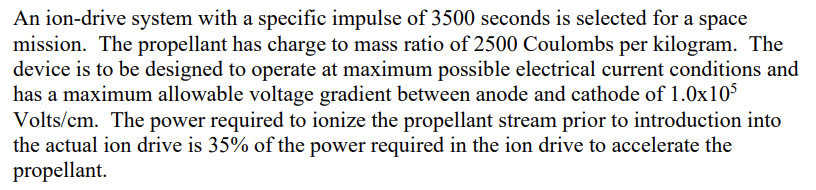

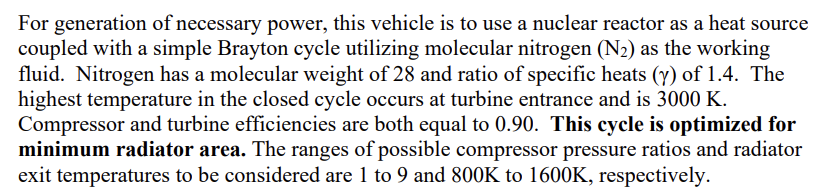

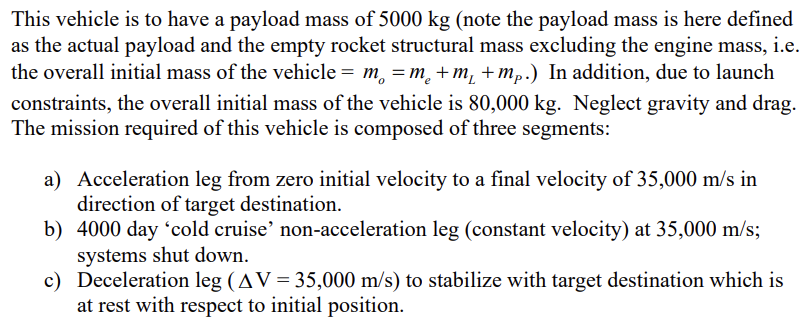

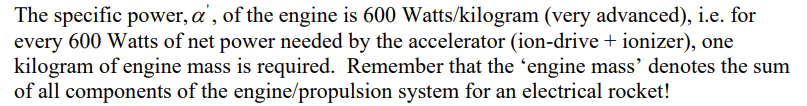

In [2]:
Isp = 3500 # sec
prop_charge = 2500 # C/kg
max_V_gradient = 1.0e+5
drive_power = 0.35 # percent/100

In [3]:
m_0 = 80_000 # Kg
m_L = 5000 # Kg

In [4]:
alpha_prime = 600 # W/kg

- The required current in the ion-drive
- The required voltage in the ion-drive
- The acceleration distance (distance between the anode and cathode in the ion-drive)
- The mass flow rate of propellant required for the ion-drive
- The thrust provided by the ion-drive
- The diameter of the (round) ion beam


- The overall (total) power supplied by the turbine in the Brayton cycle
- The power required by the compressor in the Brayton cycle
- The heat rate required from the nuclear reactor

- The radiator area required
- The mass flow rate of nitrogen gas required in the Brayton cycle
- The accelerator efficiency (exhaust kinetic energy rate/total power needed by ion drive including
ionizer)


- The firing times for the ion-drive (acceleration and deceleration legs)
- The EXACT distance traveled during this mission from beginning to end (determine and
 give acceleration distance, cruise distance, deceleration distance, and total distance)!


# Ion Drive

In [5]:
g0 = 9.81
epsilon0 = 8.85e-12
voltage = (Isp * g0 / np.sqrt(2 * prop_charge))**2
acc_distance = voltage / max_V_gradient



print(f'{voltage = } V')
print(f'{acc_distance = } cm')

voltage = 235778.44499999998 V
acc_distance = 2.3577844499999996 cm


# Trajectory

from rocket equation
- The total required engine mass
- The propellant mass used during the acceleration leg
- The propellant mass used during the deceleration leg

In [6]:
g0 = 9.81
C = Isp * g0 # effective velocity

dV_accel = 35_000
dV_deccel = 35_000
dV_tot = dV_accel + dV_deccel



m_p_func = lambda dV, m_0: m_0 * (1-np.exp(-dV/C))

m_p_accel = m_p_func(dV_accel,m_0)
m_p_deccel = m_p_func(dV_deccel,m_0-m_p_accel)
m_p_tot = m_p_accel + m_p_deccel

remaining_mass = m_0 - m_L - m_p_tot

print(f'{m_p_accel = } kg')
print(f'{m_p_deccel = } kg')
print(f'{m_p_tot = } kg')
print(f'{remaining_mass = } kg')


m_p_accel = 51134.16710815452 kg
m_p_deccel = 18450.379035096124 kg
m_p_tot = 69584.54614325064 kg
remaining_mass = 5415.453856749358 kg


Use the engine mass found previously and the specific power of the engine
- The overall (total) electrical power required by the drive (including the ionizer)

In [7]:
# power_required = engine_mass * alpha_prime
# print(f'{power_required = } W')

# Brayton cycle

In [8]:
Ru = 8314.4598 # J/mol/K
# nitrogen
molar_mass = 28 # kg/kmol
gamma = 1.4
R = Ru/molar_mass
Cp = gamma*R/(gamma-1)

T3 = 3000 # K
Nsize = 500
pi_c_list = np.linspace(1,9,Nsize)
Ta_list = np.linspace(800,1600, Nsize)

pi_c_list, Ta_list = np.meshgrid(pi_c_list,Ta_list)
pi_c_list = pi_c_list.flatten()
Ta_list = Ta_list.flatten()
eta_c = 0.90
eta_t = 0.90

epsilon = 1.0
sigma = 5.670374419e-8

- The required compressor pressure ratio and the temperature of the nitrogen gas at compressor
entrance (radiator exit)
- The temperature of the nitrogen gas at exit of compressor and at the exit of the turbine (radiator
entrance)
- The cycle (thermal) efficiency

In [10]:
def brayton_cycle(pi_c, Ta):
    pi_t = 1/pi_c
    T4 = T3 * (1 - eta_t * (1 - pi_t**((gamma-1)/gamma)))
    T2 = Ta * (1 + 1/eta_c * (pi_c**((gamma-1)/gamma) - 1))
    eta = 1 - (T4 - Ta)/(T3 - T2)
    Arad = (1/eta - 1)/(3*(T4 - Ta)*sigma*epsilon) * (1/Ta**3 - 1/T4**3)
    return T2,T4,eta,Arad


T2,T4,eta,Arad = brayton_cycle(pi_c_list,Ta_list)
for i in range(pi_c_list.size):
    if Arad[i] <= 0:
        Arad[i] = np.nan 
Arad2 = Arad[~np.isnan(Arad)]
idx = np.where(Arad == np.min(Arad2))

Ta = Ta_list[idx][0]
pi_c = pi_c_list[idx][0]
T2 = T2[idx][0]
T4 = T4[idx][0]
eta = eta[idx][0]
Arad = Arad[idx][0]

m_dot_gen = (1/eta - 1)/(T4-Ta)/Cp

#Arad*1000000
#1000000/eta
#m_dot_gen * 1000000

print(f'{pi_c = }')
print(f'{Ta = } K')
print(f'{T2 = } K')
print(f'{T4 = } K')
print(f'{eta = }')
print(f'{Arad = } m^2/W')

pi_c = 2.635270541082164
Ta = 1473.3466933867735 K
T2 = 1995.521387228242 K
T4 = 2347.047832105196 K
eta = 0.13019438382313409
Arad = 1.057791495709578e-05 m^2/W


C:\Users\rjk12\AppData\Local\Temp\ipykernel_41656\1229014095.py:25: RuntimeWarning: divide by zero encountered in divide
  Arad = (1/eta - 1)/(3*(T4 - Ta)*sigma*epsilon) * (1/Ta**3 - 1/T4**3)
